In [87]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Import modules

In [88]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import geopandas as gpd
import requests

In [89]:
import sys
from pathlib import Path

# Root directory
ROOT = Path.cwd().parent
sys.path.append(str(ROOT))

# Location of data
DATA = ROOT / "data"


# Directory for full layers
full_dir = DATA / "datasets" / "full"

# Directory for clipped layers
clipped_dir = DATA / "datasets" / "clipped"

# Directory and name of watershed boundary file
watershed_bd = DATA / "watershed_boundary"
ws_bd_name = "salinas_huc8"

# List of INMP layer names
layer_key={"INMP_map": 0, "nitrate_risk": 1, "crop_mapping": 2}
layer_names = layer_key.keys()

# Source for INMP layres
INMP_url = "https://gispublic.waterboards.ca.gov/portalserver/rest/services/Hosted/Region_3_INMP_Data_Map/FeatureServer"

# Source for watershed boundary
WBD_URL = "https://hydro.nationalmap.gov/arcgis/rest/services/wbd/MapServer"
huc8_code = "18060005"


In [90]:
# Importing modules from src

from src.data import download, clip, io
from src.features import preprocessing, transformers

# Load data

Load the full INMP data, the watershed boundary information,

Avoid downloading and clipping the datasets if local copies already exist, as both take a significant amount of time.


In [91]:
# True if the INMP data has already been fetched and saved locally
INMP_downloaded = True

# True if the layers from the INMP data have been clipped to the watershed
INMP_clipped = True

## Save/load full dataset

Set to "True" if the downloaded data is up-to-date.

In [92]:
data_current = True

Load the full INMP dataset layers.

In [93]:
full_layers = io.load_or_build(full_dir, layer_names, build=lambda: download.fetch_INMP_data(INMP_url, layer_key), force=(not data_current))

## Clip data

Clip the INMP layers to the watershed data.

In [94]:
boundary_path = watershed_bd / f"{ws_bd_name}.gpkg"

if boundary_path.exists():
    huc8 = clip.load_boundary(boundary_path)
else:
    huc8 = clip.fetch_huc8(WBD_URL, huc8_code)
    huc8.to_file(boundary_path)

huc8_layers = io.load_or_build(clipped_dir, layer_names, build = lambda: {name: clip.clip_layer(gdf, huc8) for name, gdf in full_layers.items()}, force=(not data_current))

# Data cleanup

## INMP_map

De-duplicate rows that contain the same nitrogen data.

In [95]:

huc8_layers["INMP_map"] = preprocessing.to_reports(huc8_layers["INMP_map"])

# EDA

## Outlier checks

In [96]:
from scipy.stats import zscore

### INMP_map

Some of the data in total_nitrogen_applied__lbs_ran and total_nitrogen_removed__lbs_ran seem implausible, and are likely a result of errors when reporting data. We perform a number of outlier checks to identify these data points and exclude them from our analysis.

In [109]:
reports = huc8_layers["INMP_map"]
applied = reports["total_nitrogen_applied__lbs_ran"]
removed = -reports["total_nitrogen_removed__lbs_ran"]

#### Flagging outliers in total_nitrogen_applied__lbs_ran

We begin with a straightforward z-score test.

In [124]:
def z_log(lst):
    log_vals = np.log10(lst.where(lst>0))
    return (log_vals - log_vals.mean()) / log_vals.std(ddof=0)

In [125]:
z_raw_a = zscore(applied)
z_log_a = z_log(applied)
z_thresholds = [1,2,3]
for num in z_thresholds:
    print(f"Threshold: {num}")
    print(f"|z_raw| > {num}: ")
    print(((applied[np.absolute(z_raw_a)>num])))
    print(f"z_log > {num}: ")
    print(((applied[(z_log_a)>num])))

Threshold: 1
|z_raw| > 1: 
130    30667.258947
227    19981.694245
299    78022.120000
Name: total_nitrogen_applied__lbs_ran, dtype: float64
z_log > 1: 
85      1279.849091
93      1857.435556
130    30667.258947
196     2195.068131
200     3365.196894
202     1826.483087
204     2695.883906
208     1992.069953
210     4235.852019
212     1652.151880
214     2294.000888
227    19981.694245
270     1331.084691
299    78022.120000
Name: total_nitrogen_applied__lbs_ran, dtype: float64
Threshold: 2
|z_raw| > 2: 
130    30667.258947
227    19981.694245
299    78022.120000
Name: total_nitrogen_applied__lbs_ran, dtype: float64
z_log > 2: 
130    30667.258947
227    19981.694245
299    78022.120000
Name: total_nitrogen_applied__lbs_ran, dtype: float64
Threshold: 3
|z_raw| > 3: 
130    30667.258947
227    19981.694245
299    78022.120000
Name: total_nitrogen_applied__lbs_ran, dtype: float64
z_log > 3: 
299    78022.12
Name: total_nitrogen_applied__lbs_ran, dtype: float64


We test thresholds of 1, 2, and 3. For all of these thresholds, z_raw consistently identifies the same three reports. In contrast, z_log detects one with a threshold of 3 and fourteen with a threshold of 1, agreeing with z_raw for a threshold of 2. For now, we will flag reports that exceed a z_raw threshold of 2.

In [117]:
z_threshold_a = 2

reports["flag_z_app"] = (z_raw_a > z_threshold_a)
reports["flag_z_app"] = reports["flag_z_app"].fillna(False).astype(bool)

We next use a box plot to visualize the outliers in the nitrogen applied data, looking both at the aggregate data and the data separated by year.

<Axes: xlabel='total_nitrogen_applied__lbs_ran', ylabel='year'>

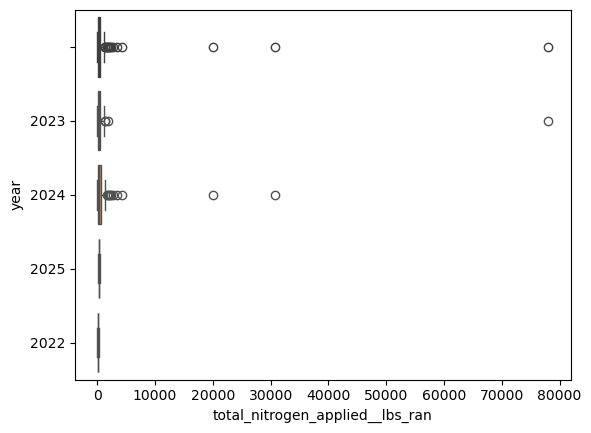

In [99]:
sns.boxplot(reports, x="total_nitrogen_applied__lbs_ran")
sns.boxplot(reports, x="total_nitrogen_applied__lbs_ran", y="year")

The plot indicates some large outliers in 2023 and 2024. We plot the nitrogen applied on a log scale as well to better visualize the regions where most of the data is concentrated.

<Axes: xlabel='total_nitrogen_applied__lbs_ran', ylabel='year'>

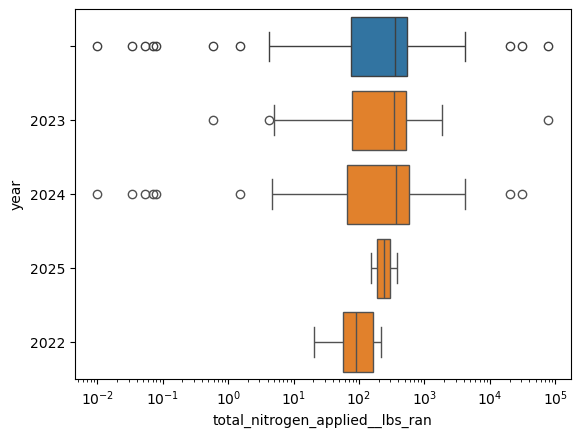

In [100]:
sns.boxplot(reports, x="total_nitrogen_applied__lbs_ran", log_scale=True)
sns.boxplot(reports, x="total_nitrogen_applied__lbs_ran", y="year", log_scale=True)

Since it is reasonable for fields to have applied very little nitrogen, we do not need to exclude the lower end. We will focus on identifying outliers in the upper end.

In [218]:
q1_a, q3_a = applied.quantile([0.25,0.75])
iqr_a = q3_a-q1_a
whis_a = 3
fence_a = q3+whis_a*iqr_a

In [208]:
reports[applied.between(q3_a+1.5*iqr_a, q3_a+3*iqr_a, inclusive="neither")].sort_values("field_id")

,member_id,field_id,year,total_nitrogen_applied__lbs_ran,total_nitrogen_removed__lbs_ran,a_r__lbs_ranch_acre_,a_r_ratio,outlier_status,crops,n_crops,...,flag_z_app,flag_box_app,flag_z_rem,flag_box_rem,flag_ratio,flag_iforest,iforest_score,flag_z,flag_box,implausible
202,AW1786,AGL020006643,2024,1826.483087,-18.334480,1808.148607,99.620119,Not Meeting 400 lb. Target,"[Cover Crop, Non-Legume (Non-Irrigated), Grape...",2,...,False,True,False,False,True,False,-0.494176,False,True,True
85,AW1561,AGL020007354,2023,1279.849091,-89.742058,1190.107033,14.261419,Not Meeting 400 lb. Target,"[Broccoli, Lettuce, Iceberg, Spinach, Baby, Sp...",4,...,False,True,False,False,False,False,-0.443799,False,True,False
86,AW1561,AGL020007354,2024,1247.565000,-86.939023,1160.625977,14.349885,Not Meeting 400 lb. Target,"[Broccoli, Lettuce, Iceberg, Spinach, Baby]",3,...,False,True,False,False,False,False,-0.440822,False,True,False
270,AW1819,AGL020007444,2023,1331.084691,-130.295505,1200.789186,10.215891,Not Meeting 400 lb. Target,"[Arugula, Wild, Broccoli, Cauliflower, Spinach...",4,...,False,True,False,False,False,False,-0.467095,False,True,False
212,AW1786,AGL020021842,2024,1652.151880,-21.439573,1630.712307,77.060856,Not Meeting 400 lb. Target,"[Cover Crop, Non-Legume (Non-Irrigated), Grape...",2,...,False,True,False,False,True,False,-0.484738,False,True,True
93,AW1561,AGL020027737,2023,1857.435556,-90.625264,1766.810291,20.495781,Not Meeting 400 lb. Target,"[Celery, Spinach, Bunch, Spring Mix]",3,...,False,True,False,False,False,True,-0.514697,False,True,False


Note that there are some fields with consistently high applied nitrogen. We choose whis_a=3 in order to not exclude these fields.

In [219]:
reports["flag_box_app"] = (applied > fence_a)

The reports flagged here all seem to be large enough that their accuracy is of potential concern.

#### Flagging outliers in total_nitrogen_removed__lbs_ran

We perform another z-score test for nitrogen removed.

In [211]:
z_raw_r = zscore(removed)
z_log_r = z_log(removed)
z_thresholds = [1,2,3]
for num in z_thresholds:
    print(f"Threshold: {num}")
    print(f"|z_raw| > {num}: ")
    print(((-removed[np.absolute(z_raw_r)>num])))
    print(f"z_log > {num}: ")
    print(((-removed[(z_log_r)>num])))

Threshold: 1
|z_raw| > 1: 
64     -2156.314473
73     -4657.775966
127    -1437.900000
129    -2158.400000
280    -5188.718200
299   -17881.500000
Name: total_nitrogen_removed__lbs_ran, dtype: float64
z_log > 1: 
64     -2156.314473
73     -4657.775966
127    -1437.900000
129    -2158.400000
280    -5188.718200
282     -806.453800
299   -17881.500000
Name: total_nitrogen_removed__lbs_ran, dtype: float64
Threshold: 2
|z_raw| > 2: 
73     -4657.775966
280    -5188.718200
299   -17881.500000
Name: total_nitrogen_removed__lbs_ran, dtype: float64
z_log > 2: 
73     -4657.775966
280    -5188.718200
299   -17881.500000
Name: total_nitrogen_removed__lbs_ran, dtype: float64
Threshold: 3
|z_raw| > 3: 
73     -4657.775966
280    -5188.718200
299   -17881.500000
Name: total_nitrogen_removed__lbs_ran, dtype: float64
z_log > 3: 
Series([], Name: total_nitrogen_removed__lbs_ran, dtype: float64)


Here, z_log with a threshold of 1 seems to identify a number of reports worth flagging. We will use this.

In [127]:
z_threshold_r = 1

reports["flag_z_rem"] = (np.absolute(z_log_r) > z_threshold_r)
reports["flag_z_rem"] = reports["flag_z_rem"].fillna(False).astype(bool)

We now use a box plot to check for outliers in total_nitrogen_removed__lbs_ran as we did earlier.

<Axes: xlabel='total_nitrogen_removed__lbs_ran', ylabel='year'>

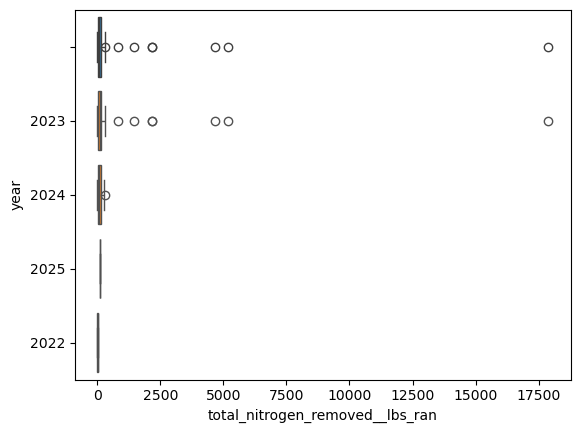

In [131]:
sns.boxplot(reports, x=removed)
sns.boxplot(reports, x=removed, y="year")

Note that there appear to be a number of outliers from 2023. We plot this again with a logrithmic scale.

<Axes: xlabel='total_nitrogen_removed__lbs_ran', ylabel='year'>

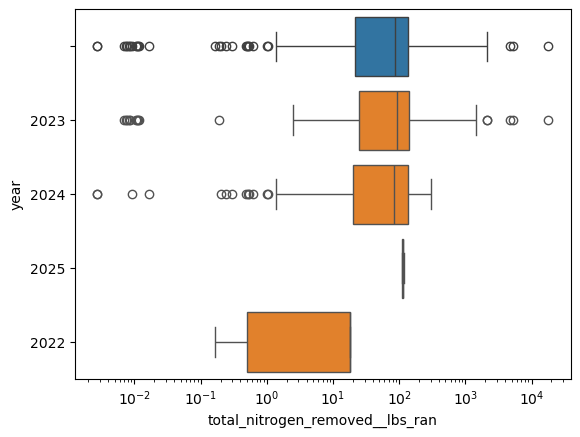

In [132]:
sns.boxplot(reports, x=removed[removed > 0], log_scale=True)
sns.boxplot(reports, x=removed[removed > 0], y="year", log_scale=True)

In [ ]:
q1_r, q3_r = removed.quantile([0.25,0.75])
iqr_r = q3_r-q1_r
whis_r = 3
fence_r = q3_r+whis_r*iqr_r

In [209]:
reports[removed.between(q3_r+1.5*iqr_r, q3_r+3*iqr_r, inclusive="neither")]

,member_id,field_id,year,total_nitrogen_applied__lbs_ran,total_nitrogen_removed__lbs_ran,a_r__lbs_ranch_acre_,a_r_ratio,outlier_status,crops,n_crops,...,flag_z_app,flag_box_app,flag_z_rem,flag_box_rem,flag_ratio,flag_iforest,iforest_score,flag_z,flag_box,implausible
269,AW1819,AGL020007443,2024,425.013091,-306.044891,118.9682,1.388728,Meeting 150 lb. Target,"[Arugula, Arugula, Wild, Broccoli (Spring/Summ...",14,...,False,False,False,False,False,False,-0.483121,False,False,False


Note that whis_r=1.5 flags row 269, which has plausible quantities of 425 lbs applied and 306 lbs removed. We choose whis_r=3 in order to not discard this row.

In [154]:
reports["flag_box_rem"] = (removed > fence_r)

Combine the applied and removed flags.

#### Flagging outliers using a_r_ratio

We analyze the ratio of applied to removed in order to find further discrepensies. To do this, we must exclude rows where the total applied is too small, as that will artificially blow up our ratios.

In [172]:
min_removed = 5    # lbs/acre

pruned_ratio = reports[removed >= min_removed]

<Axes: xlabel='a_r_ratio', ylabel='year'>

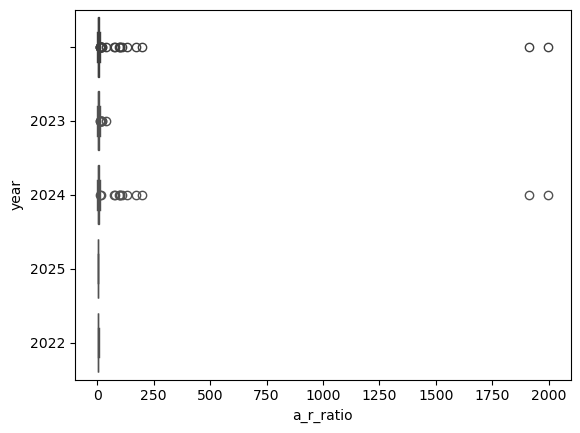

In [173]:
sns.boxplot(pruned_ratio, x="a_r_ratio")
sns.boxplot(pruned_ratio, x="a_r_ratio", y ="year")

<Axes: xlabel='a_r_ratio', ylabel='year'>

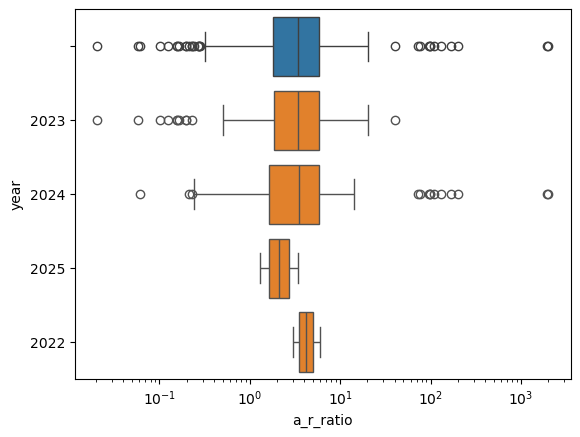

In [174]:
sns.boxplot(pruned_ratio, x="a_r_ratio", log_scale=True)
sns.boxplot(pruned_ratio, x="a_r_ratio", y ="year", log_scale=True)

In [212]:
reports[(removed >= min_removed) & ((reports["a_r_ratio"] > 10) & (reports["a_r_ratio"] < 100))].sort_values("a_r_ratio", ascending=True)

,member_id,field_id,year,total_nitrogen_applied__lbs_ran,total_nitrogen_removed__lbs_ran,a_r__lbs_ranch_acre_,a_r_ratio,outlier_status,crops,n_crops,...,flag_z_app,flag_box_app,flag_z_rem,flag_box_rem,flag_ratio,flag_iforest,iforest_score,flag_z,flag_box,implausible
168,AW1726,AGL020011788,2023,694.406364,-69.103077,625.303286,10.048849,Not Meeting 400 lb. Target,"[Broccoli, Cabbage, Carrots, Full-Sized, Cauli...",10,...,False,False,False,False,False,False,-0.378338,False,False,False
305,AW3544,AGL020010224,2023,1021.870182,-100.956207,920.913975,10.121915,Not Meeting 400 lb. Target,"[Broccoli, Brussels Sprouts, Cauliflower, Cele...",5,...,False,True,False,False,False,False,-0.404002,False,True,False
88,AW1561,AGL020007494,2024,1046.552857,-102.940283,943.612574,10.166602,Not Meeting 400 lb. Target,"[Broccoli, Carrots, Full-Sized, Cauliflower, C...",9,...,False,True,False,False,False,False,-0.403535,False,True,False
317,AW3627,AGL020013564,2024,1187.836667,-116.719333,1071.117333,10.176863,Not Meeting 400 lb. Target,"[Beans, Lima, Broccoli, Lettuce, Leaf, Onions,...",6,...,False,True,False,False,False,False,-0.433999,False,True,False
270,AW1819,AGL020007444,2023,1331.084691,-130.295505,1200.789186,10.215891,Not Meeting 400 lb. Target,"[Arugula, Wild, Broccoli, Cauliflower, Spinach...",4,...,False,True,False,False,False,False,-0.467095,False,True,False
188,AW1759,AGL020027728,2024,216.379878,-20.667460,195.712418,10.469592,Meeting 200 lb. Target,[Grapes - Wine],1,...,False,False,False,False,False,False,-0.358784,False,False,False
266,AW1819,AGL020007439,2023,852.391291,-78.000989,774.390302,10.927955,Not Meeting 400 lb. Target,"[Arugula, Wild, Broccoli, Cauliflower, Celery,...",13,...,False,True,False,False,False,False,-0.388200,False,True,False
172,AW1726,AGL020037022,2023,579.769474,-51.614581,528.154892,11.232668,Not Meeting 400 lb. Target,"[Broccoli, Broccolini, Cabbage, Cauliflower, C...",11,...,False,False,False,False,False,False,-0.373489,False,False,False
171,AW1726,AGL020037021,2024,1085.620317,-90.285292,995.335024,12.024332,Not Meeting 400 lb. Target,"[Broccoli, Carrots, Cauliflower, Cover Crop, N...",6,...,False,True,False,False,False,False,-0.410027,False,True,False
160,AW1681,AGL020001377,2023,128.380000,-10.007456,118.372544,12.828435,Meeting 150 lb. Target,[Grapes - Wine],1,...,False,False,False,False,False,False,-0.367030,False,False,False


Note the jump between ratios in Row 228 and Row 194. We observe further that this field had an extreme change in nitrogen applied between 2023 and 2024. The crops reported in 2024 include a non-irrigated cover crop in addition to grapes, so it seems likely that this report is not accurate. We then set our ratio cap to exclude this data point, along with others.

In [188]:
reports[reports["field_id"]=="AGL020006581"]

,member_id,field_id,year,total_nitrogen_applied__lbs_ran,total_nitrogen_removed__lbs_ran,a_r__lbs_ranch_acre_,a_r_ratio,outlier_status,crops,n_crops,geometry,flag_z_app,flag_box_app,flag_z_rem,flag_box_rem
193,AW1786,AGL020006581,2023,37.350735,-14.815743,22.534991,2.521017,Meeting Final 50 lb. Target,[Grapes - Wine],1,POINT (-121.22514 36.27012),False,False,False,False
194,AW1786,AGL020006581,2024,979.372746,-13.385560,965.987186,73.166363,Not Meeting 400 lb. Target,"[Cover Crop, Non-Legume (Non-Irrigated), Grape...",2,POINT (-121.22514 36.27012),False,True,False,False


In [189]:
ratio_cap = 50

reports["flag_ratio"] = (removed >= min_removed) & (reports["a_r_ratio"] > ratio_cap)

#### Combining flagged columns

In [220]:
reports["flag_z"] = (reports[["flag_z_app", "flag_z_rem"]]).any(axis=1)
reports["flag_box"] = (reports[["flag_box_app", "flag_box_rem"]]).any(axis=1)

reports["implausible"] = reports[["flag_ratio", "flag_box"]].any(axis=1)

#### Flagging outliers in multiple categories using the IsolationForest model

We use IsolationForest here to flag outliers in both the applied and removed categories.

In [221]:
from sklearn.ensemble import IsolationForest

forest_df = pd.DataFrame({"applied": applied, "removed": removed})

model = IsolationForest(n_estimators=500, contamination=cont, random_state=0)

cont = "auto"

labels = model.fit_predict(forest_df)

reports["flag_iforest"] = (labels < 0)
reports["iforest_score"] = model.score_samples(forest_df)

In [224]:
pd.crosstab(reports["flag_box"], reports["flag_iforest"])

flag_iforest,False,True
flag_box,,
False,310,0
True,3,15


In [222]:
pd.crosstab(reports["implausible"], reports["flag_iforest"])

flag_iforest,False,True
implausible,,
False,309,0
True,4,15


In [223]:
pd.crosstab(reports["flag_z"], reports["flag_iforest"])

flag_iforest,False,True
flag_z,,
False,284,6
True,29,9


We will use the "implausible" flag as defined earlier.

Cleanup for INMP_map layer.

In [225]:
# Flag reports with implausibly high applied nitrogen

huc8_layers["INMP_map"]["implausible"] = reports["implausible"]

In [ ]:
# Separates INMP_map by year

# INMP_by_year = {year: huc8_layers["INMP_map"][huc8_layers["INMP_map"]["year"]==year] for year in huc8_layers["INMP_map"]["year"].unique()}

# N_COLS = ["total_nitrogen_applied__lbs_ran", "total_nitrogen_removed__lbs_ran", "a_r__lbs_ranch_acre_", "a_r_ratio", "outlier_status"]

# KEY = ["member_id", "field_id", "year"] + N_COLS

# for year, year_gdf in INMP_by_year.items():
#     reports = (year_gdf.groupby(KEY, dropna=False, as_index=False)
#                        .agg(crops=("reported_crop_name", lambda s: sorted(set(s))),
#                             n_crops=("reported_crop_name", "nunique"),
#                             geometry=("geometry", "first")))
#     INMP_by_year[year] = gpd.GeoDataFrame(reports, geometry="geometry", crs=year_gdf.crs)


In [ ]:
from shapely.geometry import box

def make_grid(boundary, cell_size_m):
    b = boundary.to_crs(3310)                          # meters, so cell size means something
    xmin, ymin, xmax, ymax = b.total_bounds
    cells = [box(x, y, x + cell_size_m, y + cell_size_m)
             for x in np.arange(xmin, xmax, cell_size_m)
             for y in np.arange(ymin, ymax, cell_size_m)]
    grid = gpd.GeoDataFrame({"cell_id": range(len(cells))}, geometry=cells, crs=3310)
    return grid[grid.intersects(b.union_all())]       # keep only cells touching the watershed


In [ ]:
nitrogen_target = 400

gdf = huc8_layers["INMP_map"][(huc8_layers["INMP_map"]["implausible"])==False]
gdf["fails_target"] = gdf["a_r__lbs_ranch_acre_"] > nitrogen_target

pd.crosstab(gdf["fails_target"], gdf["outlier_status"])

In [ ]:
grid = make_grid(huc8, 2000)

In [ ]:
reports_on_grid = gpd.sjoin(gdf.to_crs(3310), grid, predicate="within")

In [ ]:
reports_on_grid["fails_target"] = reports_on_grid["a_r__lbs_ranch_acre_"] > nitrogen_target

In [ ]:
reports_on_grid.head()

In [ ]:
summary = reports_on_grid.groupby("cell_id").agg(
        n_reports=("fails_target", "size"), 
        n_failing=("fails_target", "sum"), 
        share_failing=("fails_target", "mean"),
        avg_a_r = ("a_r__lbs_ranch_acre_", "mean"),
        max_a_r = ("a_r__lbs_ranch_acre_", "max")
    )

In [ ]:
merged_grid = grid.merge(summary, on="cell_id", how="left")

In [ ]:
merged_grid[merged_grid["avg_a_r"]<0].shape

In [ ]:
huc8_layers["INMP_map"][huc8_layers["INMP_map"]["a_r__lbs_ranch_acre_"] < 0]

In [ ]:
import contextily as cx
from matplotlib.colors import ListedColormap


LABELS = {
    "avg_a_r": "Mean excess nitrogen (lb/acre)",
    "max_a_r": "Maximum excess nitrogen (lb/acre)",
    "share_failing": "Share of reports above the 400 lb target",
}

cmap = ListedColormap(plt.colormaps["RdBu_r"](np.linspace(0,1,256)))

for feat in features:
    ax = merged_grid.plot(
        column=feat, 
        cmap=cmap, 
        alpha=0.85,
        edgecolor = "white", 
        linewidth = 0.3,
        legend=True, 
        figsize=(8, 10),
        legend_kwds={"label": LABELS.get(feat, feat), "shrink": 0.6},
        missing_kwds={"color": "none", "edgecolor": "lightgrey", "linewidth": 0.3},
    )
    huc8.to_crs(merged_grid.crs).boundary.plot(ax=ax, color="black", linewidth=1)
    cx.add_basemap(ax, crs=merged_grid.crs, source=cx.providers.Esri.WorldGrayCanvas, alpha=0.6)
    ax.set_title(f"{LABELS.get(feat, feat)}\nSalinas watershed, 2 km cells", loc="left")
    ax.set_axis_off()


In [ ]:
import folium

m = merged_grid.explore(
    column="share_failing",
    cmap="YlOrRd",
    tiles="Esri.WorldGrayCanvas",                 # muted gray basemap
    style_kwds={"fillOpacity": 0.6, "weight": 0.3},
    tooltip=["n_reports", "n_failing", "share_failing"],
    name="Share failing target",
)
huc8.explore(m=m, style_kwds={"fill": False, "color": "black", "weight": 1.5}, name="Watershed")

folium.LayerControl().add_to(m)
m


In [ ]:
from ckanapi import RemoteCKAN

RESOURCE_ID = "c97e1fcf-8ad0-4913-9234-ba682ea73bc4"
rc = RemoteCKAN("https://data.ca.gov")          # no apikey needed for public data

result = rc.action.datastore_search(
    resource_id=RESOURCE_ID,
    filters={
        "gm_county_name": ["MONTEREY", "SAN LUIS OBISPO", "SAN BENITO"],
        "gm_chemical_vvl": ["NO3N", "NO3NO2N"],
    },
    limit=3,
)
print(result["total"])



In [ ]:
result.keys()

In [ ]:
page_size = 32000
filters = result['filters']

In [ ]:
records, offset = [], 0
while True:
    result = rc.action.datastore_search(resource_id=RESOURCE_ID, filters=filters,
                                        limit=page_size, offset=offset)
    page = result["records"]
    records += page                      # add this page's rows to the full list
    if not page or len(records) >= result["total"]:
        break
    offset += len(page)


In [ ]:
df = pd.DataFrame(records)
df.head()

In [ ]:
fields = result["fields"]
numeric_cols = [f["id"] for f in fields if (f["type"] == "numeric")]
date_cols = [f["id"] for f in fields if f["type"] == "date"]


df = df.replace("NA", np.nan)
df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors="coerce")
df[date_cols] = df[date_cols].apply(pd.to_datetime, errors="coerce")

In [ ]:
gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df["gm_longitude"], df["gm_latitude"]),
    crs="EPSG:4269",
).to_crs(4326)

In [ ]:
gdf.shape

In [ ]:
clipped_gdf = clip.clip_layer(gdf,huc8)

In [ ]:
clipped_gdf["gm_chemical_name"].unique()
nitrate_as_n = clipped_gdf[clipped_gdf["gm_chemical_name"] == "Nitrate as N"]
nitrate_nitrite = clipped_gdf[clipped_gdf["gm_chemical_name"] == "Nitrate+Nitrite"]

In [ ]:
nitrate_as_n.head()

In [ ]:
nitrate_nitrite.shape

In [ ]:
import folium

n = nitrate_as_n.explore(
    column="gm_result",
    cmap="YlOrRd",
    tiles="Esri.WorldGrayCanvas",                 # muted gray basemap
    style_kwds={"fillOpacity": 0.6, "weight": 0.3},
    # tooltip=["n_reports", "n_failing", "gm_result"],
    name="gm result",
)
huc8.explore(m=m, style_kwds={"fill": False, "color": "black", "weight": 1.5}, name="Watershed")

folium.LayerControl().add_to(n)
n
